# Домашняя работа № 4
## Анализ и аннотация клеток scRNA-seq

**Датасет:** 1k PBMCs from a Healthy Donor (10x Genomics)

**Источник:** [Zenodo — PBMC 1k](https://zenodo.org/records/14884845)

**Объект исследования:** мононуклеарные клетки периферической крови (PBMC) здорового человека, включая различные популяции иммунных клеток.

Бганцова Полина, Б06-304в

**Биологический вопрос:** можно ли выделить различные популяции иммунных клеток по профилям экспрессии генов и определить их клеточные типы?

**Цель работы:** провести контроль качества и предобработку данных scRNA-seq, выполнить кластеризацию, ручную и автоматическую аннотацию клеток, а также исследовать характерные генные программы.

## Задание 1. Выбор данных и контроль качества (QC)


In [1]:
%pip install -q "pandas==2.2.3" "anndata==0.11.4" "scanpy==1.11.1" "zarr>=2.18,<3" leidenalg scikit-misc celltypist

In [6]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

adata = sc.read_10x_h5(
    "pbmc1k_filtered_feature_bc_matrix.h5",
    gex_only=True
)
adata.var_names_make_unique()

print(adata)
print("Количество клеток:", adata.n_obs)
print("Количество генов:", adata.n_vars)
print("Митохондриальных генов:",
      adata.var_names.str.startswith("MT-").sum())

AnnData object with n_obs × n_vars = 1215 × 54872
    var: 'gene_ids', 'feature_types', 'genome'
Количество клеток: 1215
Количество генов: 54872
Митохондриальных генов: 13


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [7]:
# Обозначаем митохондриальные гены
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Рассчитываем показатели качества
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

# Просматриваем результаты
adata.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].describe()

,total_counts,n_genes_by_counts,pct_counts_mt
count,1215.000000,1215.000000,1215.000000
mean,11679.495117,3470.536626,9.315825
std,6898.807617,1224.605797,13.082885
min,513.000000,15.000000,0.000000
25%,7891.500000,2893.500000,5.630861
50%,10146.000000,3400.000000,6.736111
75%,13619.500000,4044.000000,8.196786
max,69801.000000,8409.000000,98.177681


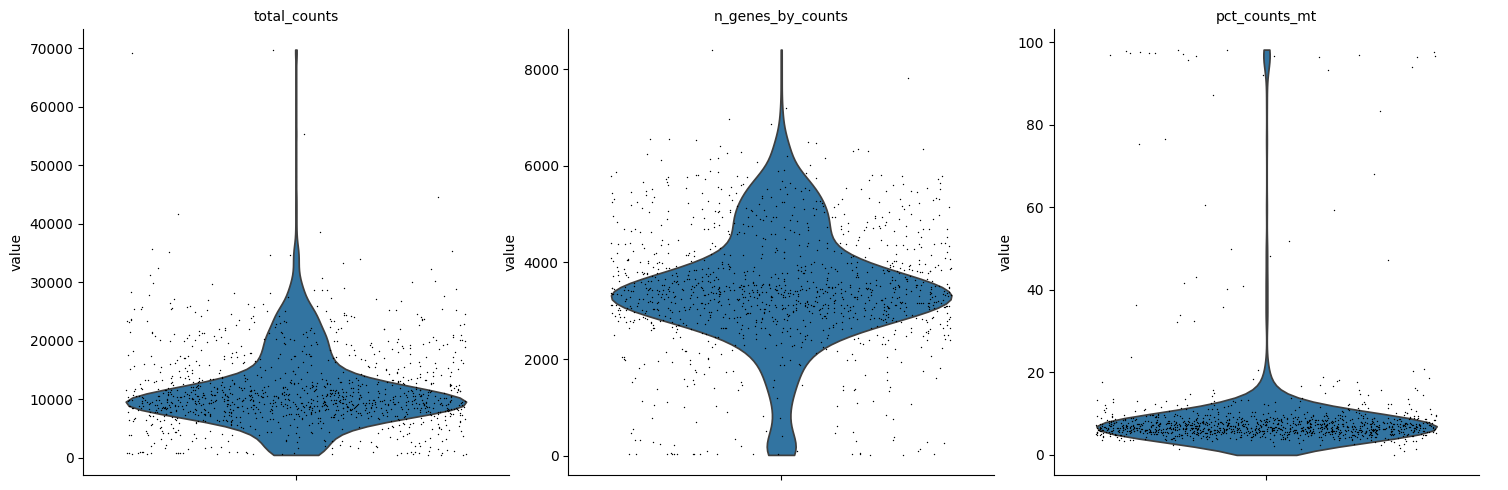

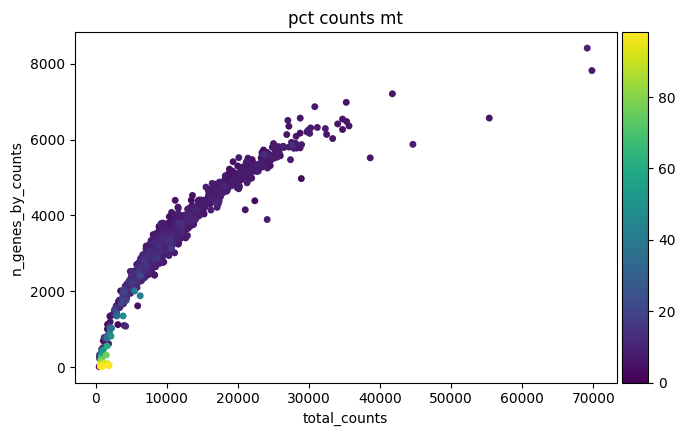

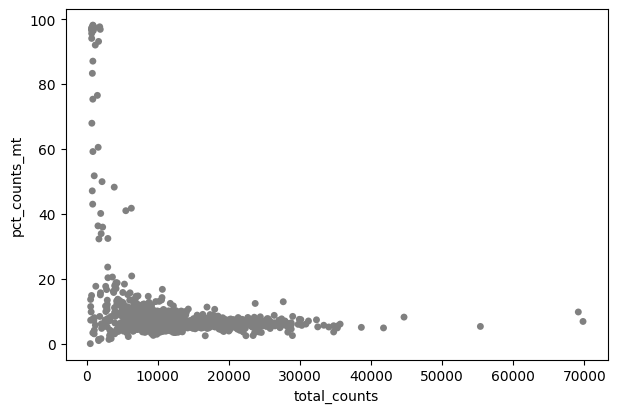

In [8]:
# Violin plots
sc.pl.violin(
    adata,
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

# Scatter plots
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="pct_counts_mt"
)

In [9]:
# Сохраняем исходные размеры датасета
n_cells_before = adata.n_obs
n_genes_before = adata.n_vars

# Фильтрация клеток
adata = adata[
    (adata.obs["n_genes_by_counts"] >= 500) &
    (adata.obs["pct_counts_mt"] < 20)
].copy()

# Удаляем гены, обнаруженные менее чем в 3 клетках
sc.pp.filter_genes(adata, min_cells=3)

print("До фильтрации:", n_cells_before, "клеток,", n_genes_before, "генов")
print("После фильтрации:", adata.n_obs, "клеток,", adata.n_vars, "генов")
print("Удалено клеток:", n_cells_before - adata.n_obs)
print("Удалено генов:", n_genes_before - adata.n_vars)

До фильтрации: 1215 клеток, 54872 генов
После фильтрации: 1161 клеток, 25266 генов
Удалено клеток: 54
Удалено генов: 29606


### Ответы и результаты

**1. Выбор датасета**

Для работы я выбрала датасет PBMC 1k от 10x Genomics. Данные скачаны с [Zenodo](https://zenodo.org/records/14884845) и загружены в AnnData.

**2. Описание данных**

В датасете представлены мононуклеарные клетки периферической крови здорового человека. Среди них могут встречаться Т- и В-лимфоциты, моноциты, NK-клетки и другие иммунные популяции.

Основная задача анализа — изучить различия в экспрессии генов между клетками и определить, к каким типам они относятся. Это цель моей работы с датасетом, а не отдельный биологический вопрос, сформулированный авторами исследования.

Изначально в наборе было **1215 клеток и 54 872 гена**.

**3. Расчёт QC-метрик**

Для каждой клетки рассчитаны три показателя: `total_counts` — общее число UMI, `n_genes_by_counts` — количество обнаруженных генов и `pct_counts_mt` — процент митохондриальных транскриптов.

**4. Анализ графиков**

На violin-графиках видно, что у большинства клеток обнаруживается примерно 3000–5000 генов, а доля митохондриальных транскриптов обычно составляет 5–10%.

На scatter-графиках заметно, что с увеличением числа UMI растёт и количество обнаруженных генов. Также есть клетки с небольшим количеством UMI и очень высокой долей митохондриальных транскриптов — вплоть до 98%. Такие клетки могут быть повреждены.

**5. Выбор порогов и фильтрация**

Я оставила клетки, в которых обнаружено не менее 500 генов и доля митохондриальных транскриптов составляет менее 20%. Первый порог позволяет убрать клетки с очень низким количеством обнаруженных генов, а второй — потенциально повреждённые клетки.

Также были удалены гены, обнаруженные менее чем в трёх клетках, поскольку они малоинформативны для дальнейшего анализа.

**6. Результаты фильтрации**

До фильтрации: **1215 клеток и 54 872 гена**.

После фильтрации: **1161 клетка и 25 266 генов**.

Таким образом, было удалено 54 клетки и 29 606 генов. После QC данные готовы к дальнейшей обработке.

## Задание 2. Нормализация и высоковариабельные гены (HVG)

In [10]:
# Сохраняем исходные UMI после QC
adata.layers["counts"] = adata.X.copy()

# Нормализация на 10 000 UMI на клетку
sc.pp.normalize_total(adata, target_sum=1e4)

# Логарифмирование экспрессии
sc.pp.log1p(adata)

print("Нормализация и логарифмирование выполнены")
print(adata)

Нормализация и логарифмирование выполнены
AnnData object with n_obs × n_vars = 1161 × 25266
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'log1p'
    layers: 'counts'


In [11]:
# Выбираем 2000 высоковариабельных генов
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

print("Выбрано HVG:", adata.var["highly_variable"].sum())

Выбрано HVG: 2000


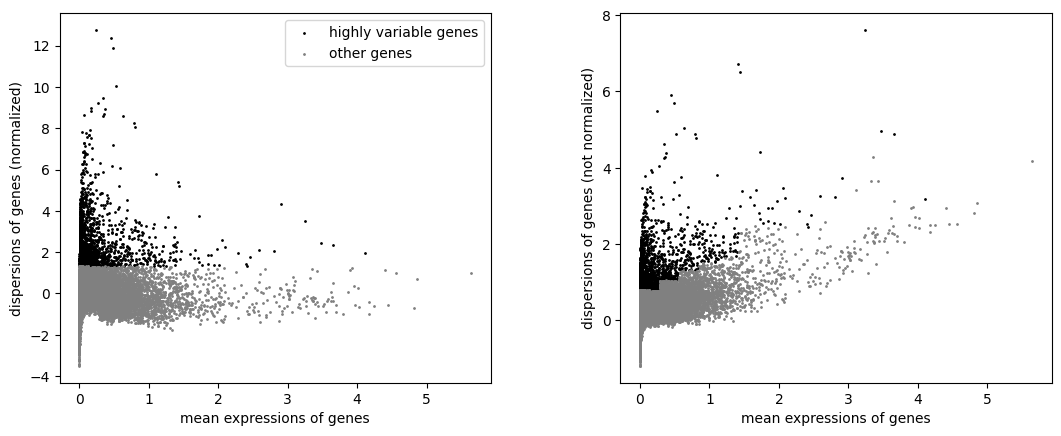

In [12]:
# Визуализация высоковариабельных генов
sc.pl.highly_variable_genes(adata)

In [13]:
# 10 генов с наибольшей нормализованной вариабельностью
top10_hvg = (
    adata.var[adata.var["highly_variable"]]
    .sort_values("dispersions_norm", ascending=False)
    .head(10)
)

print("10 наиболее высоковариабельных генов:")
display(top10_hvg[["means", "dispersions_norm"]])

10 наиболее высоковариабельных генов:


,means,dispersions_norm
IGHG2,0.247862,12.759035
IGHG3,0.451037,12.386306
IGHGP,0.492762,11.898869
GP1BB,0.526541,10.059477
IGHG1,0.343053,9.450809
CLU,0.269238,9.244310
PTCRA,0.165705,8.969813
CAVIN2,0.372565,8.940953
ACRBP,0.168748,8.816555
TUBB1,0.354662,8.691829


###Ответы и результаты

**1. Нормализация и логарифмирование**

Экспрессию нормализовали на 10 000 UMI на клетку и логарифмировали с помощью `log1p`, чтобы уменьшить влияние различий в глубине секвенирования.

**2. Выбор HVG**

С помощью `sc.pp.highly_variable_genes()` и метода `seurat` выбрали наиболее вариабельные гены.

**3. График HVG**

На графиках чёрным отмечены HVG, серым — остальные гены. Выбранные гены имеют повышенную вариабельность относительно своего уровня экспрессии.

**4. Количество HVG**

Выбрано **2000 генов** из 25 266.

**5. Топ-10 HVG и их функции**

| Ген | Функция |
|---|---|
| IGHG2 | Тяжёлая цепь IgG |
| IGHG3 | Тяжёлая цепь IgG3 |
| IGHGP | Предположительно псевдоген иммуноглобулина |
| GP1BB | Адгезия тромбоцитов |
| IGHG1 | Тяжёлая цепь IgG1 |
| CLU | Защита клеток, регуляция воспаления |
| PTCRA | Развитие Т-лимфоцитов |
| CAVIN2 | Формирование кавеол клеточной мембраны |
| ACRBP | Белок акросомы сперматозоидов |
| TUBB1 | Микротрубочки тромбоцитов |

Среди HVG есть гены иммуноглобулинов и тромбоцитов, что может отражать различия между клеточными популяциями.

**Зачем выбирать HVG?**

HVG лучше отражают различия между клетками. Использование всех генов может добавлять шум и увеличивать вычислительную нагрузку при PCA и кластеризации.

## Задание 3. PCA и кластеризация

In [14]:
# PCA по 2000 высоковариабельным генам
sc.tl.pca(
    adata,
    n_comps=50,
    mask_var="highly_variable",
    svd_solver="arpack"
)

print("PCA выполнен")
print("Размерность PCA:", adata.obsm["X_pca"].shape)

PCA выполнен
Размерность PCA: (1161, 50)


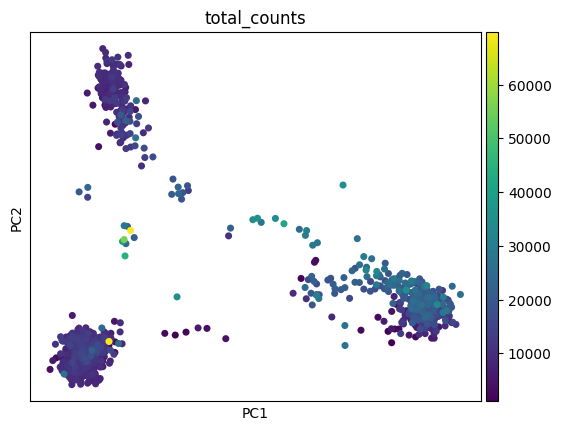

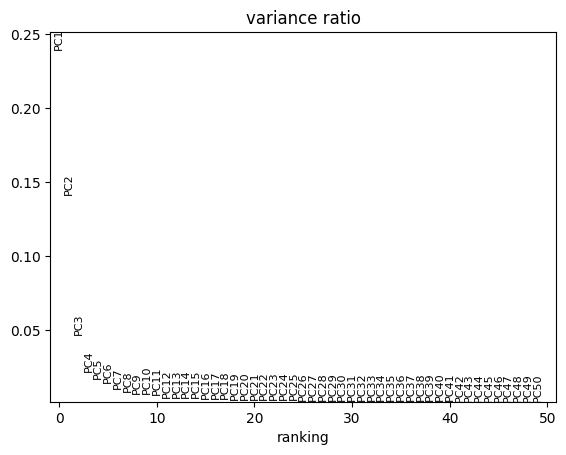

In [15]:
# Распределение клеток по первым двум главным компонентам
sc.pl.pca(adata, color="total_counts")

# Доля дисперсии, объясняемая главными компонентами
sc.pl.pca_variance_ratio(adata, log=False, n_pcs=50)

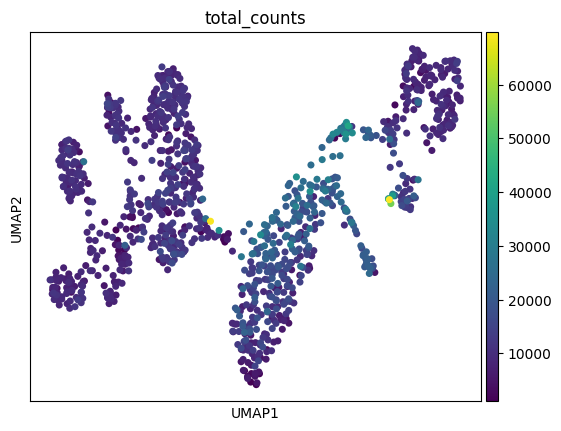

In [16]:
# Строим граф соседства по результатам PCA
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)

# Рассчитываем UMAP
sc.tl.umap(adata)

# Визуализация UMAP
sc.pl.umap(adata, color="total_counts")

In [17]:
# Кластеризация Leiden при двух значениях resolution
sc.tl.leiden(
    adata,
    resolution=0.3,
    key_added="leiden_0.3",
    flavor="igraph",
    directed=False
)

sc.tl.leiden(
    adata,
    resolution=1.0,
    key_added="leiden_1.0",
    flavor="igraph",
    directed=False
)

print("Количество кластеров при resolution=0.3:",
      adata.obs["leiden_0.3"].nunique())

print("Количество кластеров при resolution=1.0:",
      adata.obs["leiden_1.0"].nunique())

Количество кластеров при resolution=0.3: 8
Количество кластеров при resolution=1.0: 12


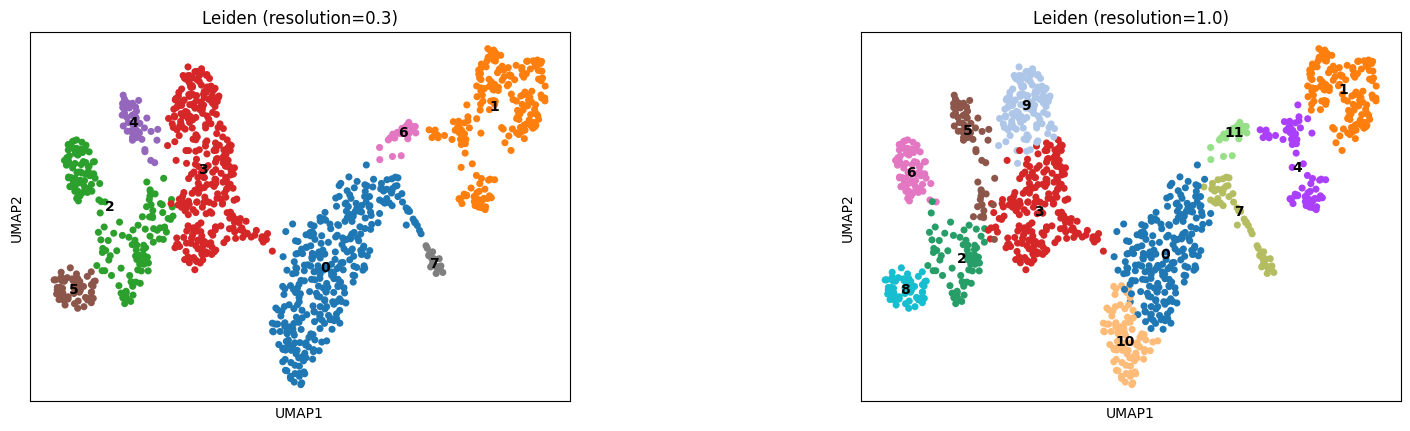

In [18]:
# Сравнение кластеризации при двух значениях resolution
sc.pl.umap(
    adata,
    color=["leiden_0.3", "leiden_1.0"],
    wspace=0.4,
    legend_loc="on data",
    title=["Leiden (resolution=0.3)", "Leiden (resolution=1.0)"]
)

In [19]:
# Количество клеток в каждом кластере
print("Размеры кластеров (resolution=0.3):")
print(adata.obs["leiden_0.3"].value_counts().sort_index())

print("\nРазмеры кластеров (resolution=1.0):")
print(adata.obs["leiden_1.0"].value_counts().sort_index())

# Сопоставление кластеров при двух значениях resolution
print("\nСравнение кластеров:")
display(pd.crosstab(
    adata.obs["leiden_0.3"],
    adata.obs["leiden_1.0"]
))

Размеры кластеров (resolution=0.3):
leiden_0.3
0    331
1    203
2    167
3    311
4     48
5     56
6     25
7     20
Name: count, dtype: int64

Размеры кластеров (resolution=1.0):
leiden_1.0
0     211
1     136
2      68
3     201
4      67
5      64
6      70
7      55
8      56
9     123
10     85
11     25
Name: count, dtype: int64

Сравнение кластеров:


leiden_1.0,0,1,2,3,4,5,6,7,8,9,10,11
leiden_0.3,,,,,,,,,,,,
0,211,0,0,0,0,0,0,35,0,0,85,0
1,0,136,0,0,67,0,0,0,0,0,0,0
2,0,0,68,13,0,16,70,0,0,0,0,0
3,0,0,0,188,0,0,0,0,0,123,0,0
4,0,0,0,0,0,48,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,56,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,25
7,0,0,0,0,0,0,0,20,0,0,0,0


###Ответы и результаты

**1. PCA**

PCA выполнен по 2000 HVG. Для 1161 клетки рассчитано 50 главных компонент.

**2. Графики PCA**

На PCA видны несколько отдельных групп клеток. Первая компонента объясняет около 25% вариации, вторая — около 15%. Вклад остальных компонент постепенно уменьшается.

**3. Граф соседства и UMAP**

Граф соседства построен по 30 главным компонентам с `n_neighbors=15`. На UMAP заметны несколько обособленных групп клеток.

**4. Кластеризация Leiden**

Кластеризация выполнена при двух значениях `resolution`: 0.3 и 1.0.

**5. Сравнение UMAP**

При `resolution=0.3` получилось 8 кластеров, при `resolution=1.0` — 12. На втором UMAP некоторые крупные группы разделились на более мелкие.

**6. Количество и размеры кластеров**

| Resolution | Количество кластеров | Размеры кластеров |
|---|---|---|
| 0.3 | 8 | От 20 до 331 клетки |
| 1.0 | 12 | От 25 до 211 клеток |

**Ответы на вопросы**

**Как `resolution` влияет на количество кластеров?** При увеличении `resolution` алгоритм выделяет больше кластеров, разделяя крупные группы на мелкие.

**Какие кластеры разделились?** Например, кластер 0 разделился на 0, 7 и 10, кластер 2 — на 2, 3, 5 и 6, а кластер 3 — на 3 и 9.

**Каждый ли кластер соответствует отдельному типу клеток?** Нет. Один тип клеток может разделяться на несколько кластеров из-за различий в состоянии или активности клеток. Для определения клеточных типов нужно проверить маркерные гены.

## Задание 4. Ручная аннотация клеток

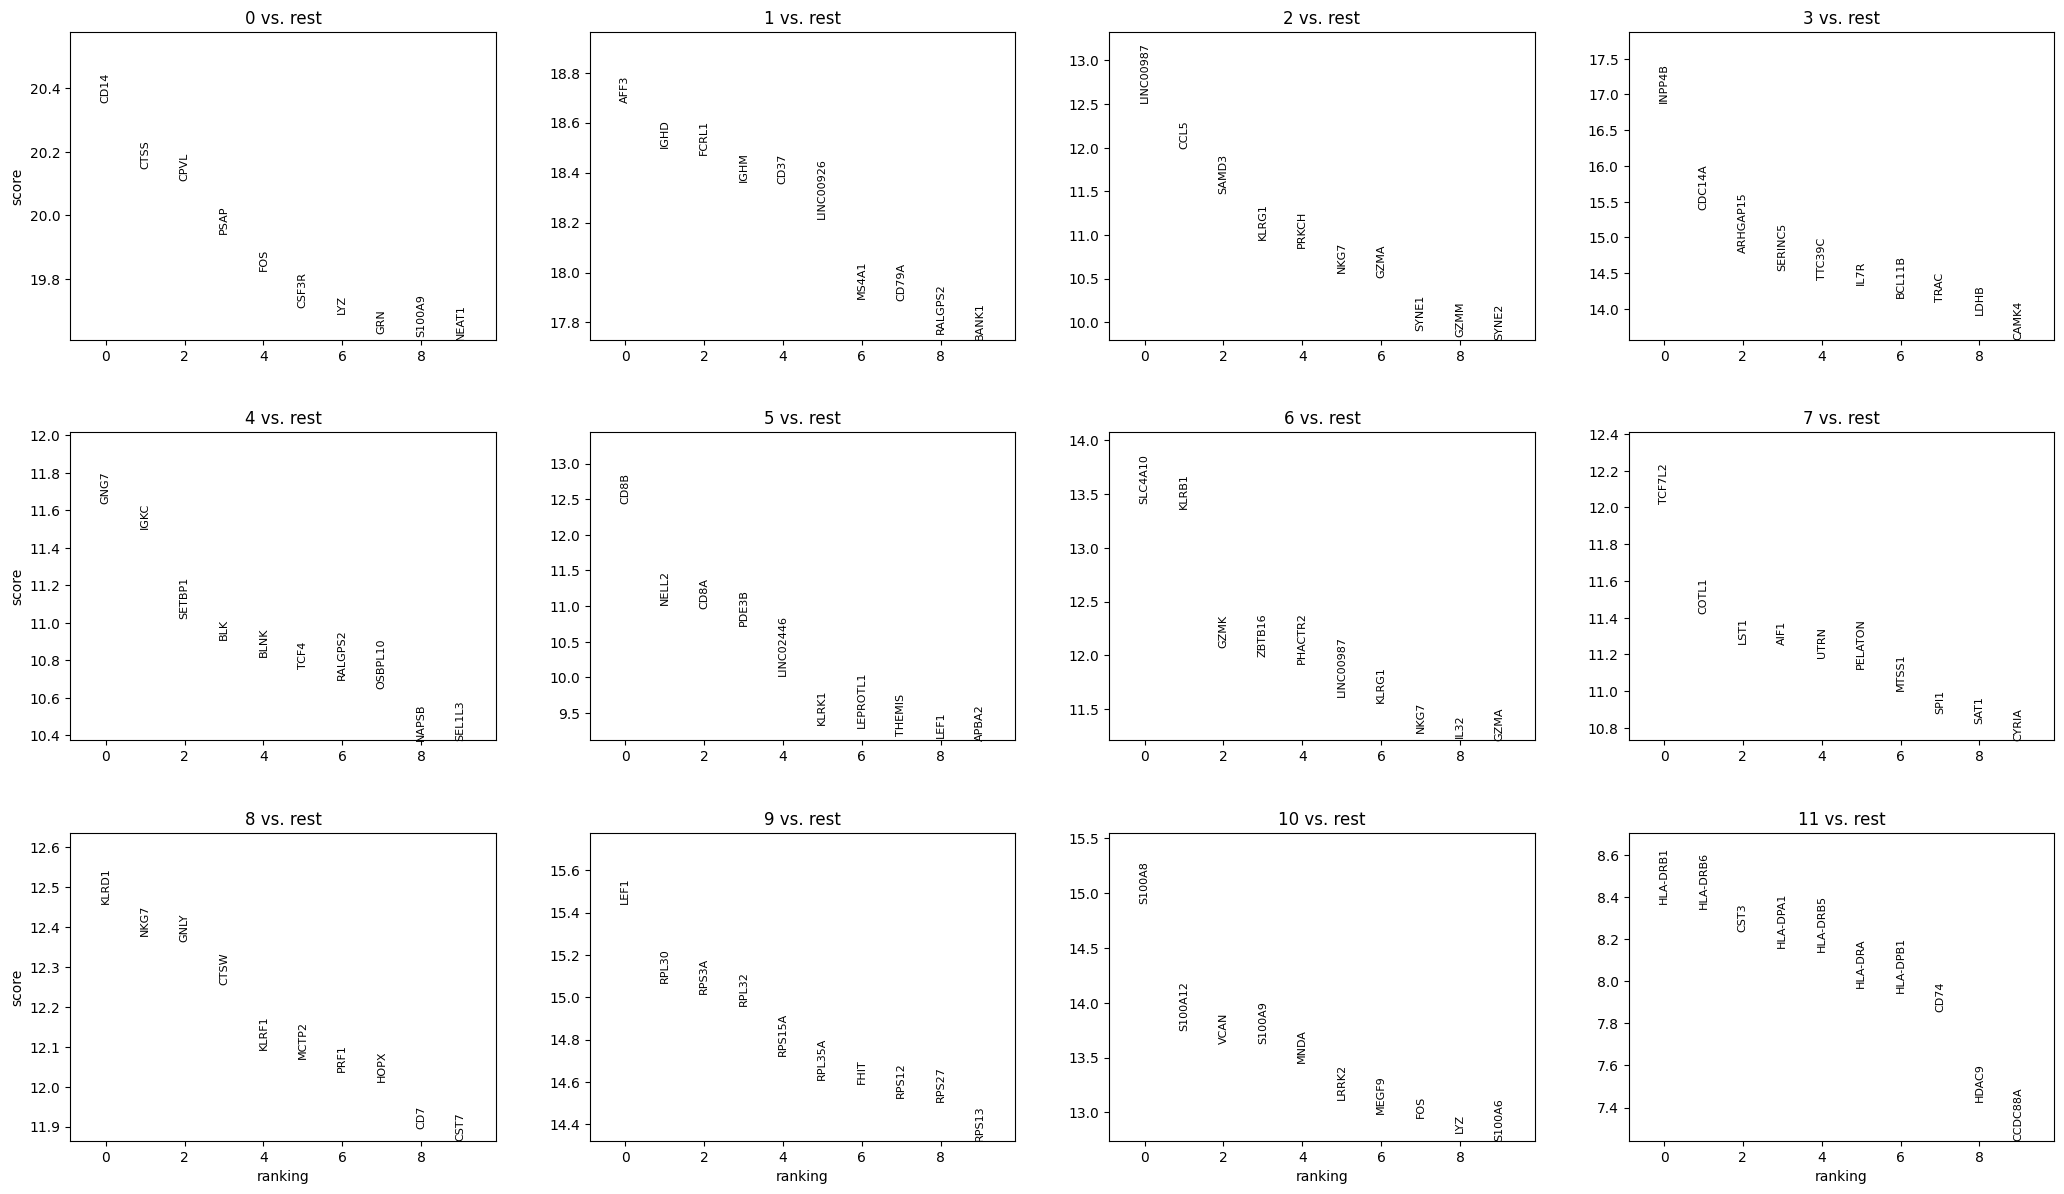

In [20]:
# Находим маркерные гены для 12 кластеров Leiden
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden_1.0",
    method="wilcoxon",
    use_raw=False
)

# Выводим 10 лучших маркеров каждого кластера
sc.pl.rank_genes_groups(
    adata,
    n_genes=10,
    sharey=False
)

In [21]:
# Таблица маркерных генов каждого кластера
markers = sc.get.rank_genes_groups_df(
    adata,
    group=None
)

# Для каждого маркера рассчитываем среднюю экспрессию
# и долю клеток, в которых он обнаружен
from scipy import sparse

results = []

for cluster in adata.obs["leiden_1.0"].cat.categories:
    genes = markers.loc[
        markers["group"] == cluster, "names"
    ].head(5)

    cells = adata.obs["leiden_1.0"] == cluster

    for gene in genes:
        x = adata[cells, gene].X
        if sparse.issparse(x):
            x = x.toarray()
        x = np.asarray(x).ravel()

        results.append({
            "cluster": cluster,
            "gene": gene,
            "mean_expression": round(x.mean(), 3),
            "pct_expressing": round((x > 0).mean() * 100, 1)
        })

marker_summary = pd.DataFrame(results)

display(marker_summary)

,cluster,gene,mean_expression,pct_expressing
0,0,CD14,1.629,98.6
1,0,CTSS,3.313,100.0
2,0,CPVL,1.874,100.0
3,0,PSAP,2.552,100.0
4,0,FOS,3.986,100.0
5,1,AFF3,3.691,100.0
6,1,IGHD,2.309,97.8
7,1,FCRL1,2.436,98.5
8,1,IGHM,3.348,99.3
9,1,CD37,2.830,100.0


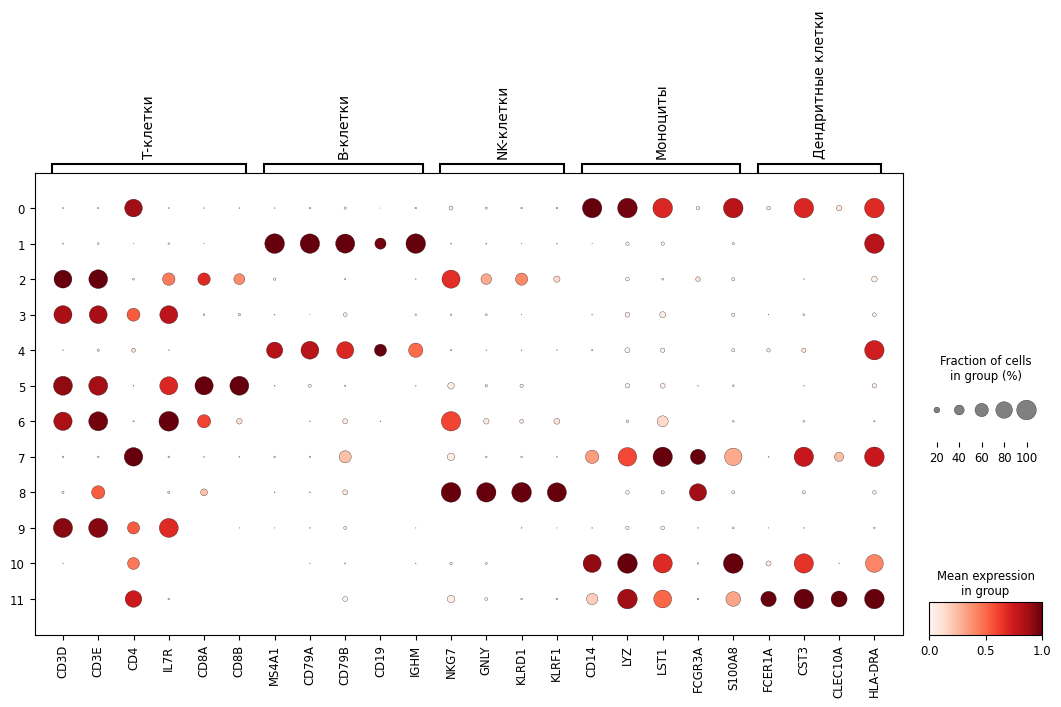

In [22]:
# Известные маркеры основных иммунных популяций
marker_genes = {
    "T-клетки": ["CD3D", "CD3E", "CD4", "IL7R", "CD8A", "CD8B"],
    "B-клетки": ["MS4A1", "CD79A", "CD79B", "CD19", "IGHM"],
    "NK-клетки": ["NKG7", "GNLY", "KLRD1", "KLRF1"],
    "Моноциты": ["CD14", "LYZ", "LST1", "FCGR3A", "S100A8"],
    "Дендритные клетки": ["FCER1A", "CST3", "CLEC10A", "HLA-DRA"]
}

# Оставляем только гены, присутствующие в датасете
marker_genes = {
    group: [gene for gene in genes if gene in adata.var_names]
    for group, genes in marker_genes.items()
}

sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby="leiden_1.0",
    standard_scale="var",
    figsize=(13, 6)
)

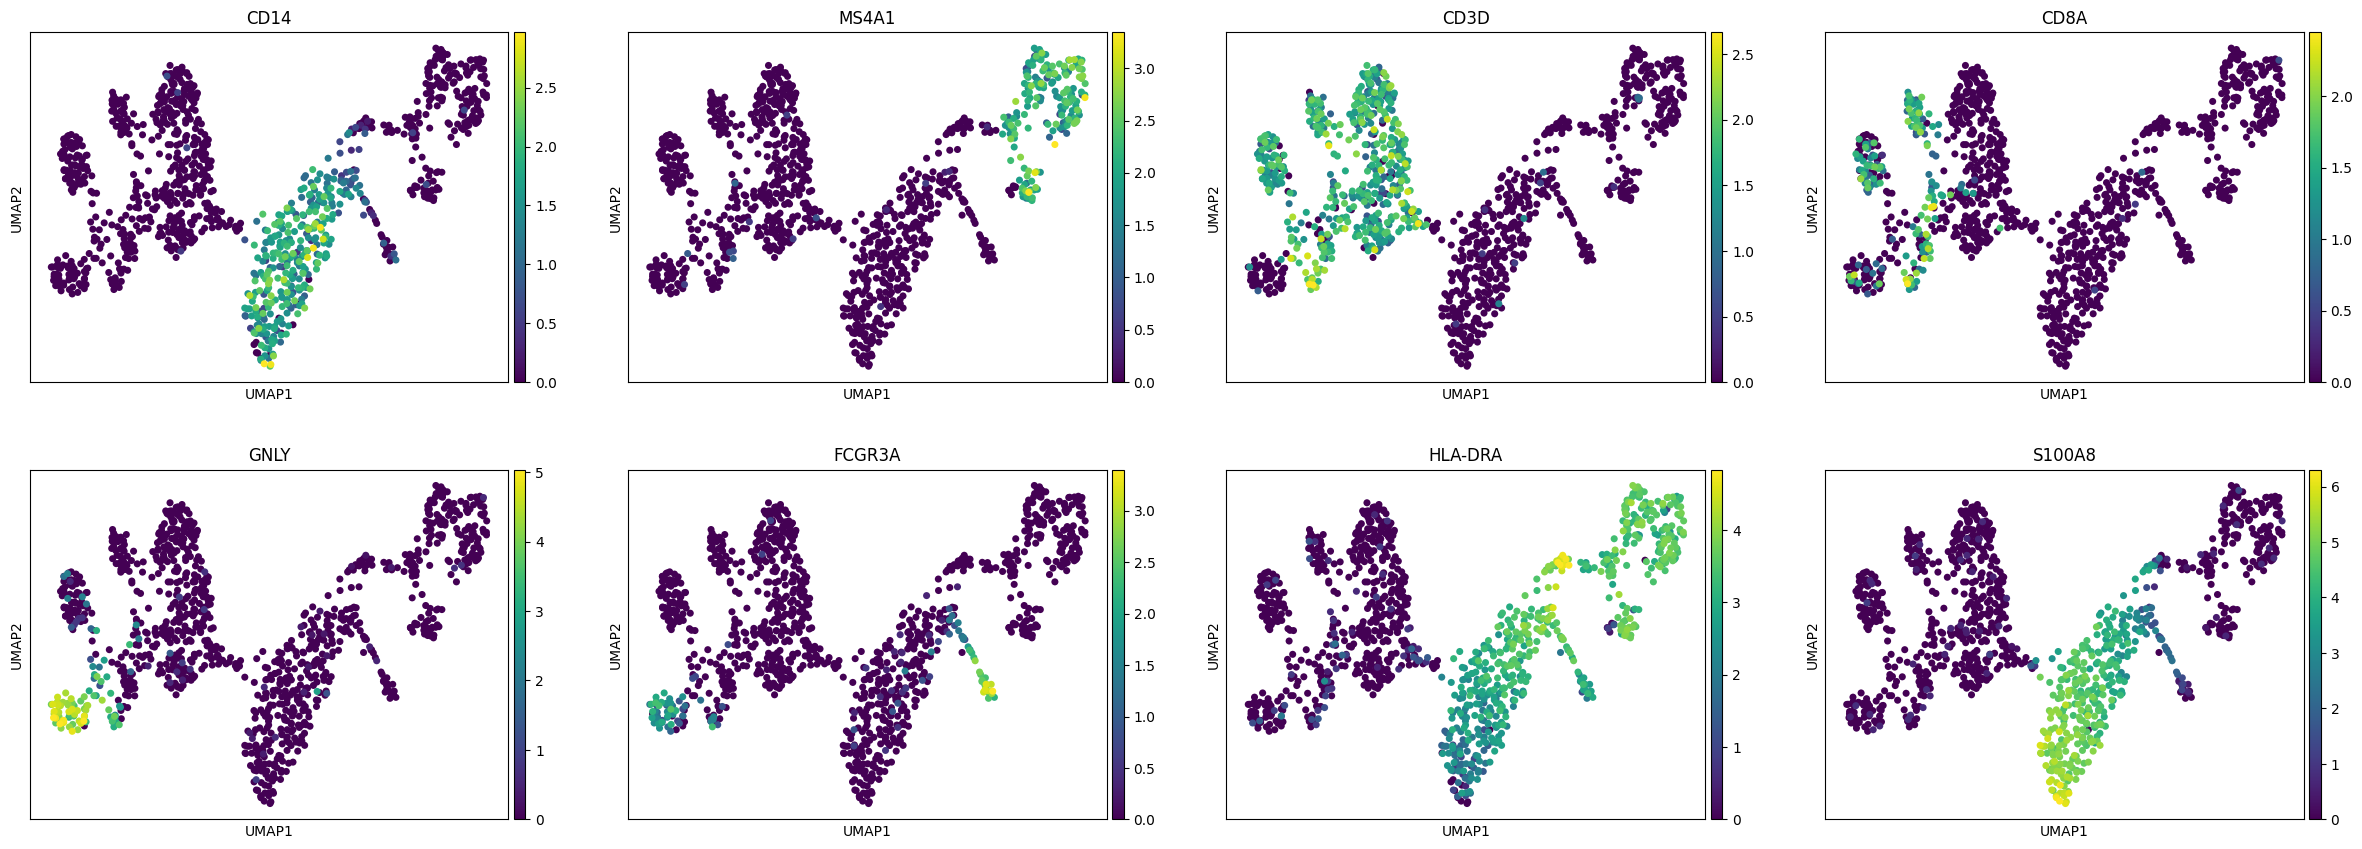

In [23]:
# UMAP с экспрессией характерных маркеров
sc.pl.umap(
    adata,
    color=["CD14", "MS4A1", "CD3D", "CD8A", "GNLY", "FCGR3A", "HLA-DRA", "S100A8"],
    ncols=4,
    cmap="viridis"
)

manual_cell_type
CD14+ monocytes           211
B cells                   203
CD4+ T cells              201
Naive T cells             123
S100A8+ monocytes          85
MAIT-like T cells          70
Cytotoxic T cells          68
CD8+ T cells               64
NK cells                   56
FCGR3A+ monocytes          55
APCs (Unknown subtype)     25
Name: count, dtype: int64


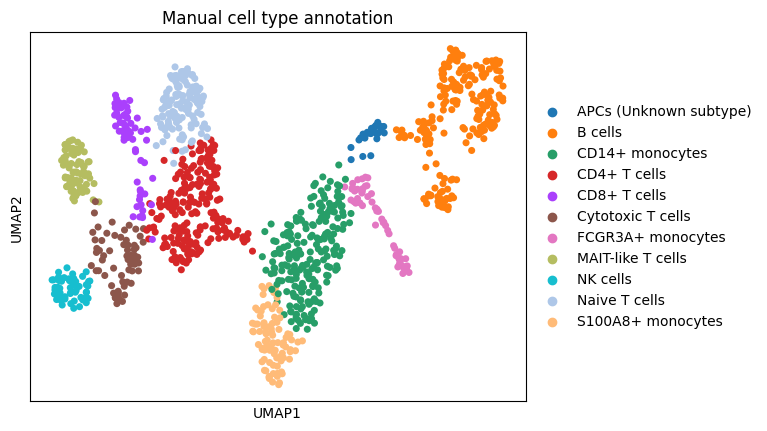

In [24]:
# Предполагаемые клеточные типы по маркерным генам
cell_types = {
    "0": "CD14+ monocytes",
    "1": "B cells",
    "2": "Cytotoxic T cells",
    "3": "CD4+ T cells",
    "4": "B cells",
    "5": "CD8+ T cells",
    "6": "MAIT-like T cells",
    "7": "FCGR3A+ monocytes",
    "8": "NK cells",
    "9": "Naive T cells",
    "10": "S100A8+ monocytes",
    "11": "APCs (Unknown subtype)"
}

# Сохраняем аннотацию в AnnData
adata.obs["manual_cell_type"] = (
    adata.obs["leiden_1.0"]
    .astype(str)
    .map(cell_types)
    .astype("category")
)

# Проверяем результат
print(adata.obs["manual_cell_type"].value_counts())

# UMAP с ручной аннотацией
sc.pl.umap(
    adata,
    color="manual_cell_type",
    legend_loc="right margin",
    title="Manual cell type annotation"
)

###Ответы и результаты

**1. Поиск маркерных генов**

Для 12 кластеров Leiden (`resolution=1.0`) найдены маркерные гены с помощью `sc.tl.rank_genes_groups()` и метода Wilcoxon.

**2. Экспрессия маркеров**

Для пяти ведущих маркеров каждого кластера рассчитаны средняя экспрессия и доля клеток, в которых обнаружен ген. Например, `CD14` экспрессируется в 98,6% клеток кластера 0, а `GNLY` — в 98,2% клеток кластера 8.

**3. Определение клеточных типов**

Предполагаемые типы определены по известным маркерам иммунных клеток. Например, `CD3D` характерен для T-клеток, `MS4A1` — для B-клеток, `GNLY` — для NK-клеток, а `CD14` — для моноцитов.

**4. Визуализация**

На dotplot и UMAP видно, что маркеры преимущественно экспрессируются в соответствующих клеточных популяциях.

**5. Ручная аннотация**

Каждому кластеру присвоен предполагаемый клеточный тип. Результаты сохранены в `adata.obs["manual_cell_type"]`.

**Итоговая таблица аннотации**

| Кластер | Предполагаемый тип | Маркеры | Обоснование |
|---|---|---|---|
| 0 | CD14⁺ моноциты | CD14, LYZ, CTSS | Моноцитарные маркеры |
| 1 | B-клетки | CD79A, IGHM, MS4A1 | Маркеры B-лимфоцитов |
| 2 | Цитотоксические T-клетки | CD3D, CCL5, KLRG1 | T-клеточные и цитотоксические маркеры |
| 3 | CD4⁺ T-клетки | CD3D, CD4, IL7R | T-клеточные маркеры и CD4 |
| 4 | B-клетки | IGKC, BLK, CD79A | Маркеры B-лимфоцитов |
| 5 | CD8⁺ T-клетки | CD8A, CD8B, CD3D | Маркеры CD8⁺ T-клеток |
| 6 | MAIT-подобные T-клетки | KLRB1, SLC4A10, ZBTB16 | Характерное сочетание маркеров |
| 7 | FCGR3A⁺ моноциты | FCGR3A, LST1, AIF1 | Моноцитарные маркеры |
| 8 | NK-клетки | GNLY, NKG7, KLRD1 | Маркеры NK-клеток |
| 9 | Наивные T-клетки | LEF1, CD3D, CD3E | T-клеточные маркеры и LEF1 |
| 10 | S100A8⁺ моноциты | S100A8, S100A9, VCAN | Маркеры воспалительных моноцитов |
| 11 | Антигенпрезентирующие клетки (тип не уточнён) | HLA-DRA, HLA-DRB1, CST3 | Маркеры презентации антигена, недостаточно данных для точного типа |

Аннотация предварительная: для некоторых кластеров могут потребоваться дополнительные маркеры. Кластер 11 оставлен без точного подтипа, поскольку имеющихся данных недостаточно для уверенного определения.

## Задание 5. Автоматическая аннотация клеток

In [25]:
import celltypist
from celltypist import models

# Загружаем референсную модель для иммунных клеток человека
models.download_models(model="Immune_All_Low.pkl")

model = models.Model.load("Immune_All_Low.pkl")

print("Модель загружена:", model)

Модель загружена: CellTypist model with 98 cell types and 6639 features
    date: 2022-07-16 00:20:42.927778
    details: immune sub-populations combined from 20 tissues of 18 studies
    source: https://doi.org/10.1126/science.abl5197
    version: v2
    cell types: Age-associated B cells, Alveolar macrophages, ..., pDC precursor
    features: A1BG, A2M, ..., ZYX


In [26]:
# Автоматическая аннотация с помощью CellTypist
predictions = celltypist.annotate(
    adata,
    model=model,
    majority_voting=False
)

# Сохраняем результаты в AnnData
adata.obs["celltypist_cell_type"] = (
    predictions.predicted_labels["predicted_labels"]
    .reindex(adata.obs_names)
    .values
)

# Посмотрим, какие типы клеток определила модель
print(adata.obs["celltypist_cell_type"].value_counts())

celltypist_cell_type
Classical monocytes            323
Tcm/Naive helper T cells       227
Naive B cells                  128
MAIT cells                      78
Tem/Effector helper T cells     59
Tcm/Naive cytotoxic T cells     55
Memory B cells                  50
CD16+ NK cells                  49
Tem/Trm cytotoxic T cells       35
Tem/Temra cytotoxic T cells     34
Non-classical monocytes         33
Regulatory T cells              21
DC2                             15
pDC                              8
Age-associated B cells           8
Plasma cells                     8
Megakaryocytes/platelets         6
CD16- NK cells                   6
DC1                              5
Follicular helper T cells        4
ILC3                             4
Cycling T cells                  1
CRTAM+ gamma-delta T cells       1
Megakaryocyte precursor          1
Mono-mac                         1
gamma-delta T cells              1
Name: count, dtype: int64


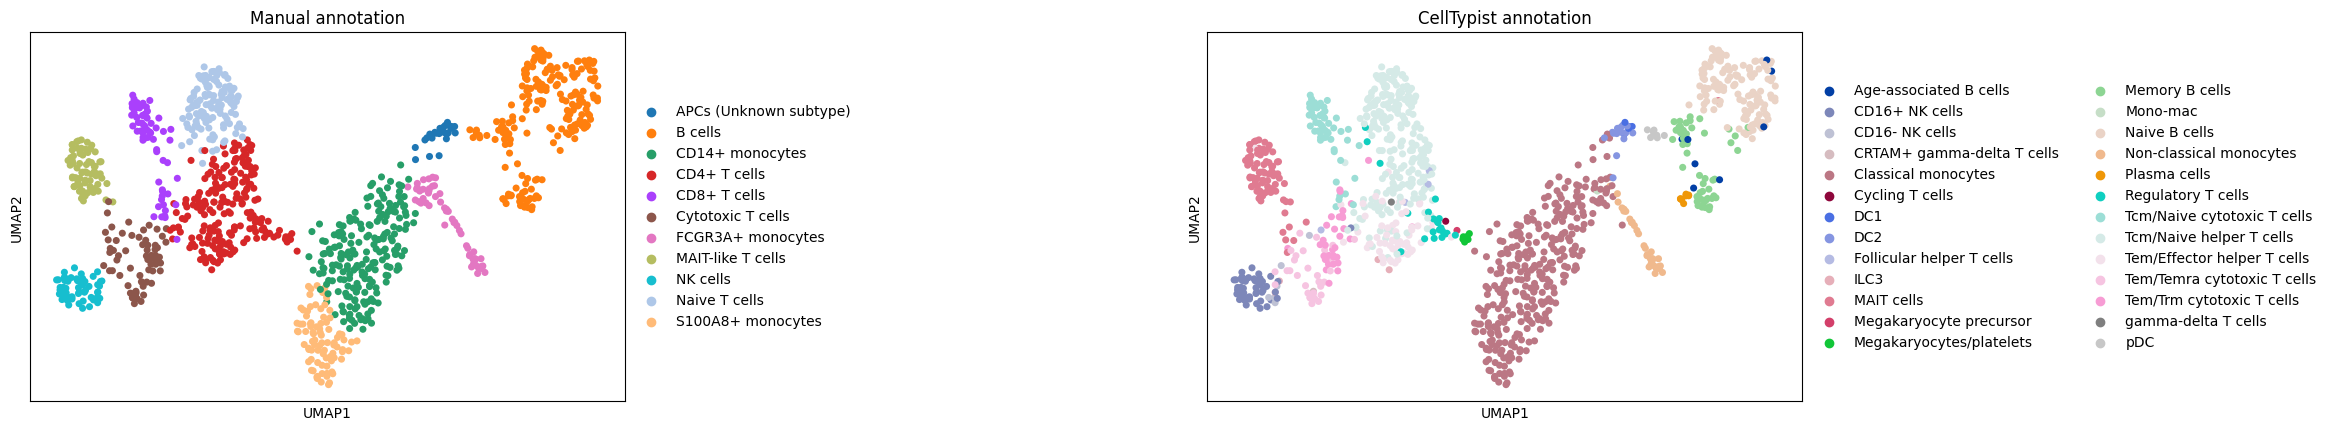

In [27]:
# Сравнение ручной и автоматической аннотации на UMAP
sc.pl.umap(
    adata,
    color=["manual_cell_type", "celltypist_cell_type"],
    wspace=0.8,
    legend_loc="right margin",
    title=["Manual annotation", "CellTypist annotation"]
)

In [28]:
# Сравниваем ручную и автоматическую аннотации
comparison = pd.crosstab(
    adata.obs["manual_cell_type"],
    adata.obs["celltypist_cell_type"]
)

display(comparison)

celltypist_cell_type,Age-associated B cells,CD16+ NK cells,CD16- NK cells,CRTAM+ gamma-delta T cells,Classical monocytes,Cycling T cells,DC1,DC2,Follicular helper T cells,ILC3,...,Non-classical monocytes,Plasma cells,Regulatory T cells,Tcm/Naive cytotoxic T cells,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,gamma-delta T cells,pDC
manual_cell_type,,,,,,,,,,,,,,,,,,,,,
APCs (Unknown subtype),0,0,0,0,6,0,5,14,0,0,...,0,0,0,0,0,0,0,0,0,0
B cells,8,0,0,0,0,0,0,0,0,0,...,0,8,0,0,0,0,0,0,0,8
CD14+ monocytes,0,0,0,0,211,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CD4+ T cells,0,1,0,0,1,1,0,0,3,2,...,0,0,18,0,107,56,0,4,1,0
CD8+ T cells,0,0,0,0,0,0,0,0,0,0,...,0,0,0,54,1,1,1,7,0,0
Cytotoxic T cells,0,0,2,1,0,0,0,0,1,0,...,0,0,0,0,0,1,31,24,0,0
FCGR3A+ monocytes,0,0,0,0,20,0,0,1,0,0,...,33,0,0,0,0,0,0,0,0,0
MAIT-like T cells,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
NK cells,0,48,4,0,0,0,0,0,0,2,...,0,0,0,0,0,0,2,0,0,0


###Ответы и результаты

**1. Инструмент автоматической аннотации**

Для автоматического определения клеточных типов использован CellTypist.

**2. Референсная модель**

Выбрана модель `Immune_All_Low.pkl`, подходящая для иммунных клеток человека. Она содержит 98 клеточных типов.

**3. Автоматическая аннотация**

CellTypist определил 26 клеточных типов. Наиболее многочисленные — классические моноциты (323 клетки), наивные/центральные CD4⁺ T-клетки (227) и наивные B-клетки (128).

**4. UMAP**

На UMAP показаны результаты автоматической аннотации. CellTypist выделяет больше подтипов, чем ручная аннотация.

**5. Сравнение с ручной аннотацией**

С помощью `pd.crosstab()` построена таблица сопряжённости. Основные клеточные популяции в двух аннотациях в целом совпадают.

**Ответы на вопросы**

**Где аннотации совпали?** Наиболее уверенно — для CD14⁺-моноцитов (211 из 211 клеток), S100A8⁺-моноцитов (85 из 85), CD8⁺ T-клеток (54 из 64 отнесены к наивным/центральным цитотоксическим T-клеткам) и NK-клеток (52 из 56 отнесены к двум подтипам NK).

**Где наблюдаются расхождения?** CellTypist разделил B- и T-клетки на более мелкие подтипы. Среди FCGR3A⁺-моноцитов 33 клетки определены как неклассические, а 20 — как классические. В кластере антигенпрезентирующих клеток обнаружены DC1, DC2 и моноциты.

**С чем связаны расхождения?** Ручная аннотация основана на нескольких маркерных генах, а CellTypist учитывает более широкий профиль экспрессии. Кроме того, близкие клеточные подтипы могут иметь сходные маркеры.

**Какая аннотация более обоснованна?** Для основных клеточных популяций обе аннотации согласуются. CellTypist даёт более подробную классификацию, но редкие подтипы и спорные предсказания требуют проверки по маркерам. Поэтому наиболее надёжно использовать оба подхода вместе.

## Задание 6. Субкластеризация

In [29]:
# Выбираем кластер 3 — CD4+ T-клетки
adata_sub = adata[
    adata.obs["leiden_1.0"] == "3"
].copy()

print("Клеток в выбранном кластере:", adata_sub.n_obs)
print("Генов:", adata_sub.n_vars)

# Проверяем автоматическую аннотацию внутри кластера
print("\nТипы клеток по CellTypist:")
print(adata_sub.obs["celltypist_cell_type"].value_counts())

Клеток в выбранном кластере: 201
Генов: 25266

Типы клеток по CellTypist:
celltypist_cell_type
Tcm/Naive helper T cells       107
Tem/Effector helper T cells     56
Regulatory T cells              18
Megakaryocytes/platelets         6
Tem/Trm cytotoxic T cells        4
Follicular helper T cells        3
ILC3                             2
CD16+ NK cells                   1
Cycling T cells                  1
Classical monocytes              1
Megakaryocyte precursor          1
gamma-delta T cells              1
Name: count, dtype: int64


In [30]:
# Выбираем HVG внутри CD4+ T-клеток
sc.pp.highly_variable_genes(
    adata_sub,
    n_top_genes=2000,
    flavor="seurat"
)

# PCA по новым HVG
sc.tl.pca(
    adata_sub,
    n_comps=30,
    mask_var="highly_variable",
    svd_solver="arpack"
)

print("Выбрано HVG:", adata_sub.var["highly_variable"].sum())
print("Размерность PCA:", adata_sub.obsm["X_pca"].shape)

Выбрано HVG: 2000
Размерность PCA: (201, 30)


In [31]:
# Граф соседства внутри CD4+ T-клеток
sc.pp.neighbors(
    adata_sub,
    n_neighbors=10,
    n_pcs=20
)

# UMAP
sc.tl.umap(adata_sub)

# Субкластеризация Leiden
sc.tl.leiden(
    adata_sub,
    resolution=0.5,
    key_added="subcluster",
    flavor="igraph",
    directed=False
)

print("Количество субкластеров:",
      adata_sub.obs["subcluster"].nunique())

print("\nРазмеры субкластеров:")
print(adata_sub.obs["subcluster"].value_counts().sort_index())

Количество субкластеров: 4

Размеры субкластеров:
subcluster
0    44
1    78
2    31
3    48
Name: count, dtype: int64


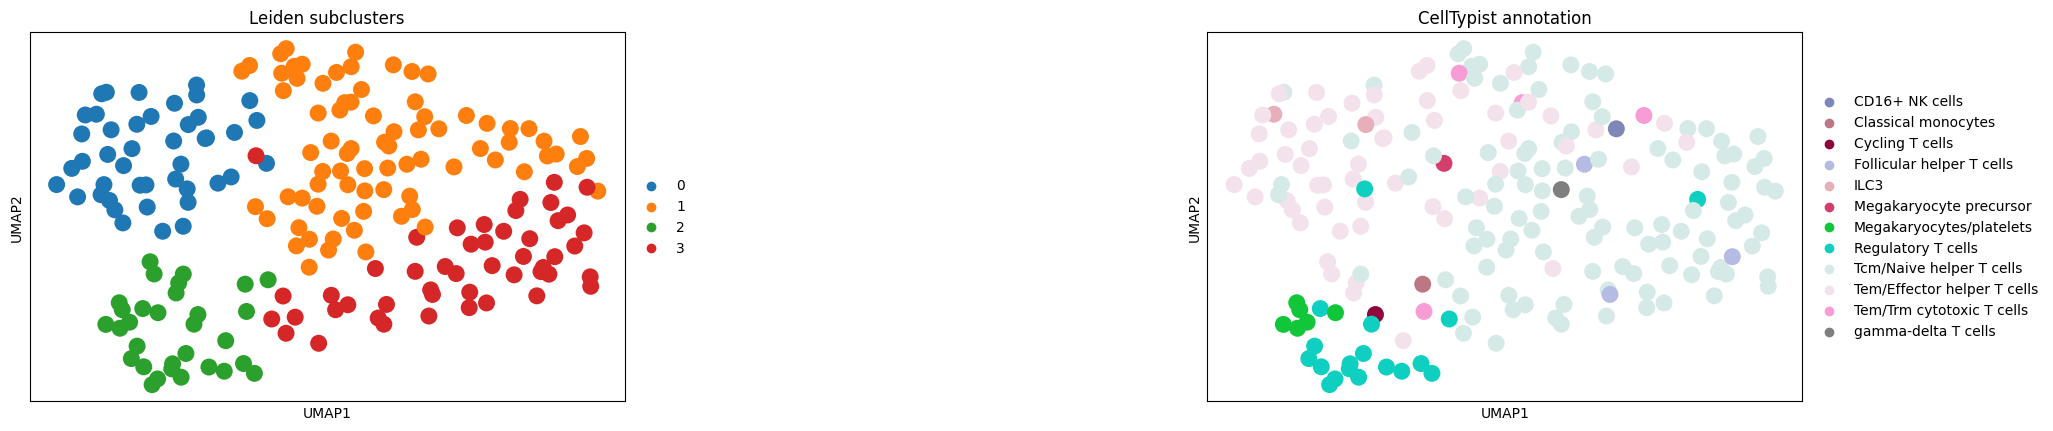

In [32]:
# UMAP субкластеров и сравнение с CellTypist
sc.pl.umap(
    adata_sub,
    color=["subcluster", "celltypist_cell_type"],
    wspace=0.8,
    title=["Leiden subclusters", "CellTypist annotation"]
)

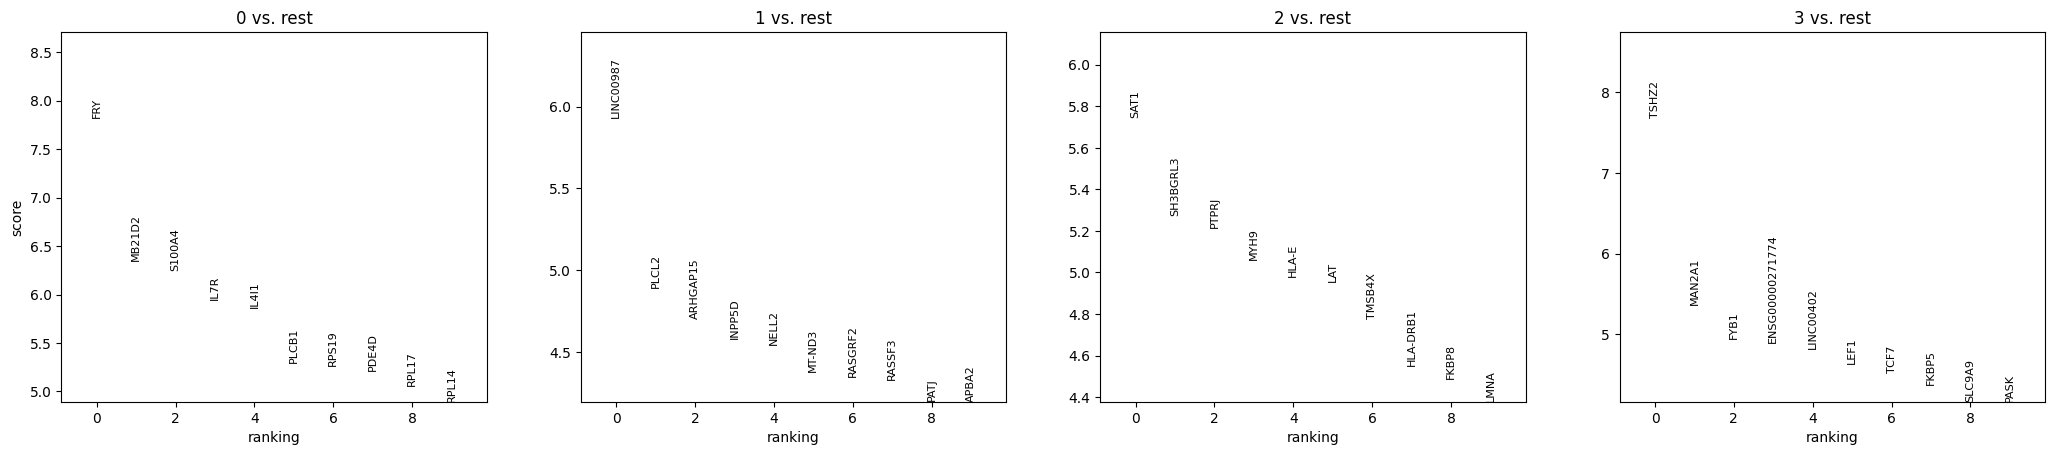

In [33]:
# Поиск маркерных генов четырёх субкластеров
sc.tl.rank_genes_groups(
    adata_sub,
    groupby="subcluster",
    method="wilcoxon",
    use_raw=False
)

# Выводим по 10 ведущих маркеров каждого субкластера
sc.pl.rank_genes_groups(
    adata_sub,
    n_genes=10,
    sharey=False
)

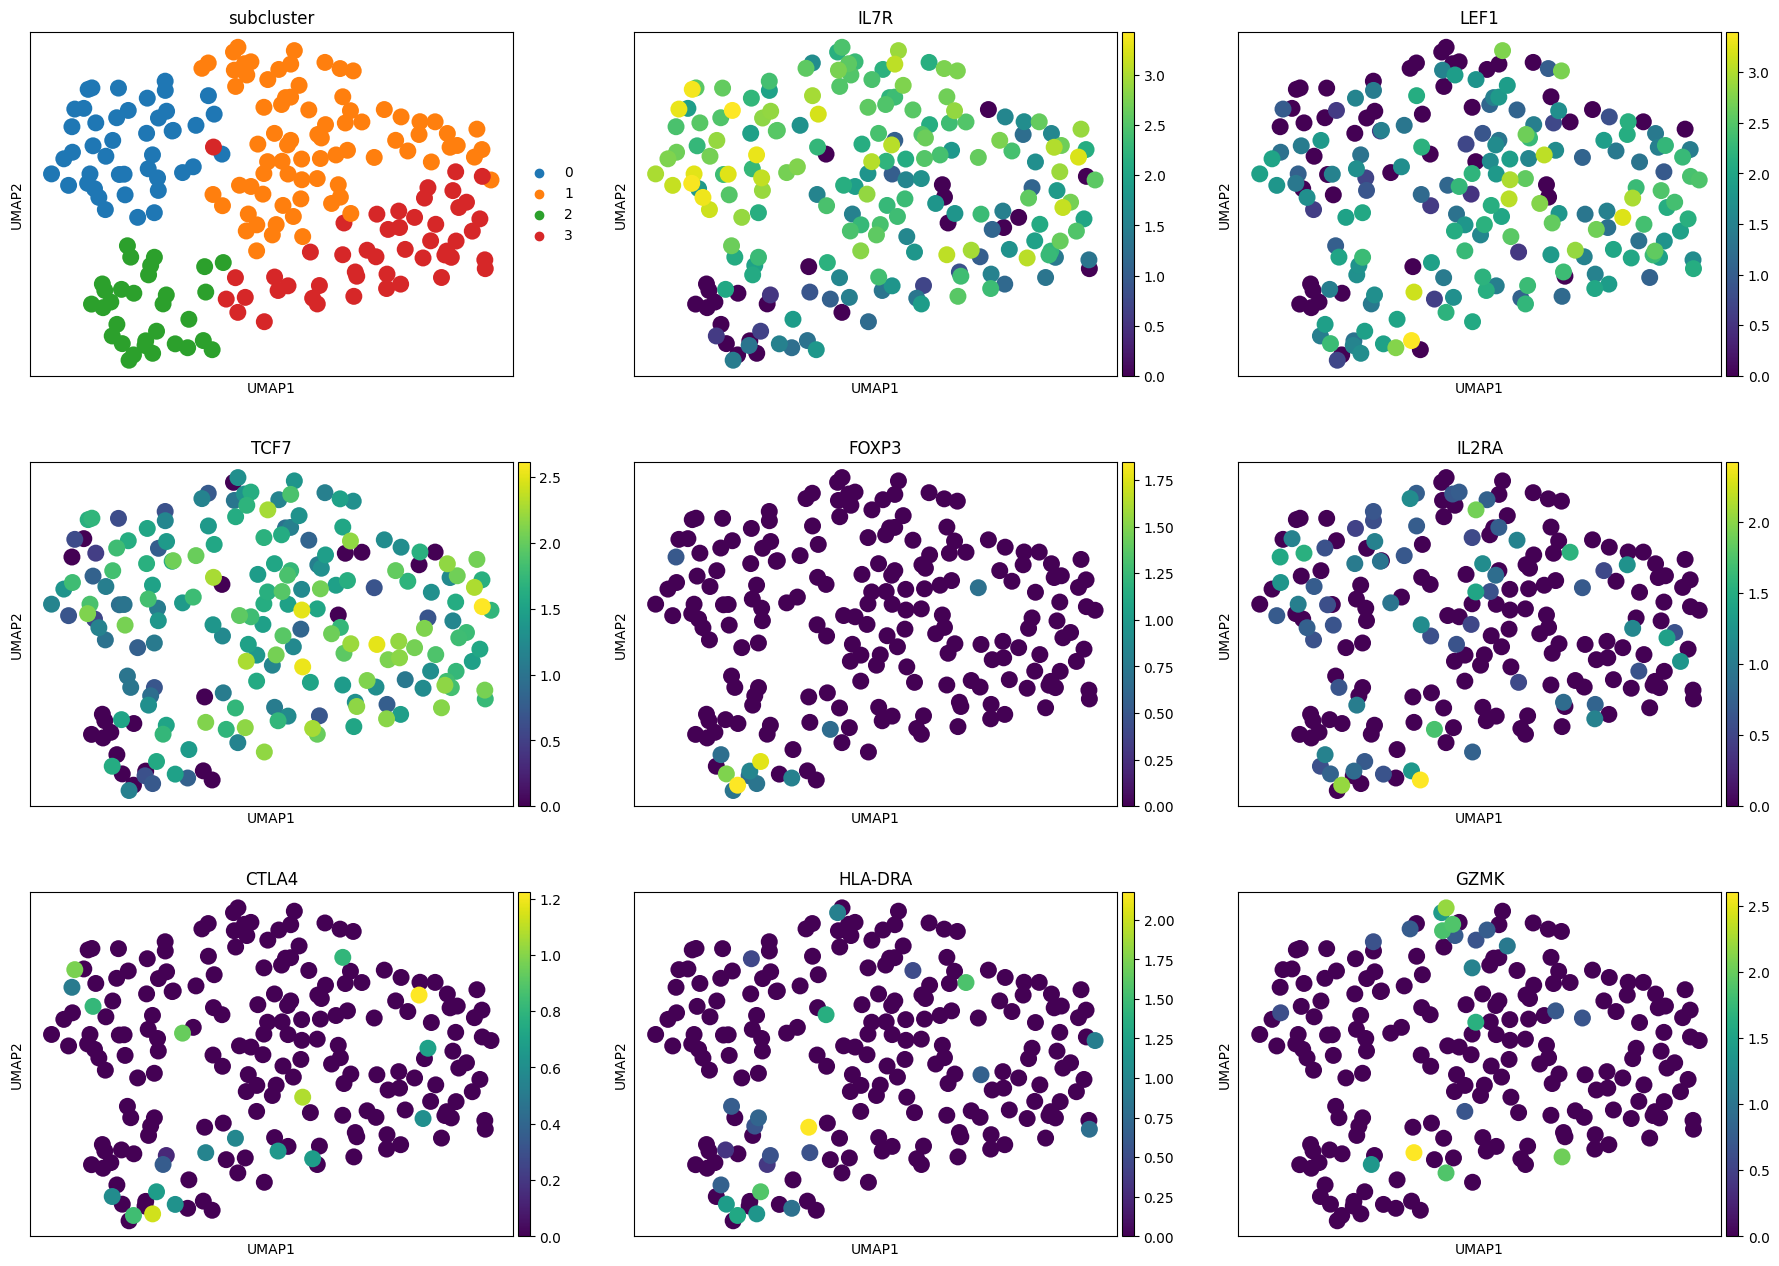

In [34]:
# Проверяем маркеры предполагаемых состояний CD4+ T-клеток
genes_to_check = [
    "IL7R", "LEF1", "TCF7",
    "FOXP3", "IL2RA", "CTLA4",
    "HLA-DRA", "GZMK"
]

genes_to_check = [
    gene for gene in genes_to_check
    if gene in adata_sub.var_names
]

sc.pl.umap(
    adata_sub,
    color=["subcluster"] + genes_to_check,
    ncols=3,
    cmap="viridis"
)

In [35]:
# Сопоставляем субкластеры с автоматической аннотацией
subcluster_comparison = pd.crosstab(
    adata_sub.obs["subcluster"],
    adata_sub.obs["celltypist_cell_type"]
)

display(subcluster_comparison.T)

subcluster,0,1,2,3
celltypist_cell_type,,,,
CD16+ NK cells,0,1,0,0
Classical monocytes,0,0,1,0
Cycling T cells,0,0,1,0
Follicular helper T cells,0,1,0,2
ILC3,2,0,0,0
Megakaryocyte precursor,1,0,0,0
Megakaryocytes/platelets,0,0,6,0
Regulatory T cells,1,0,15,2
Tcm/Naive helper T cells,7,55,2,43


### Ответы и результаты

**1. Выбор клеток**

Для субкластеризации выбран кластер 3 (`leiden_1.0`), содержащий 201 CD4⁺ T-клетку. Для него создан отдельный объект `adata_sub`.

**2. Повторный анализ**

Заново выбраны 2000 HVG, выполнен PCA (30 компонент), построены граф соседства и UMAP. При `resolution=0.5` получено 4 субкластера.

**3. UMAP**

На UMAP видны четыре группы размером 44, 78, 31 и 48 клеток.

**4. Маркерные гены**

Для каждого субкластера найдены характерные гены методом Wilcoxon. Среди них `IL7R`, `IL4I1`, `LEF1`, `TCF7`, `SAT1`, `HLA-DRB1`.

**5. Предполагаемые клеточные состояния**

| Субкластер | Клеток | Предполагаемый тип или состояние | Обоснование |
|---|---:|---|---|
| 0 | 44 | Эффекторные CD4⁺ T-клетки | `IL7R`, `IL4I1`; CellTypist определил 33 клетки как эффекторные |
| 1 | 78 | Наивные/центральные CD4⁺ T-клетки | 55 клеток определены CellTypist как Tcm/Naive |
| 2 | 31 | Treg-обогащённая группа | Экспрессия `FOXP3`, `IL2RA`, `CTLA4`; 15 клеток определены как Treg |
| 3 | 48 | Наивные/центральные CD4⁺ T-клетки | `LEF1`, `TCF7`; 43 клетки определены как Tcm/Naive |

**Ответы на вопросы**

**Удалось ли разделить исходную популяцию на биологически интерпретируемые субпопуляции?**

Да, выделены группы, обогащённые эффекторными, наивными и регуляторными CD4⁺ T-клетками. Однако не все субкластеры соответствуют отдельным клеточным типам.

**Какие гены отличают новые субкластеры?**

Для субкластера 0 характерны `FRY`, `IL7R`, `IL4I1`; для 1 — `PLCL2`, `NELL2`; для 2 — `SAT1`, `HLA-DRB1`; для 3 — `LEF1`, `TCF7`.

**Почему эти различия могли быть незаметны при первоначальной кластеризации всех клеток?**

При анализе всех PBMC основную вариацию создают различия между крупными клеточными типами. Повторный выбор HVG и PCA только для CD4⁺ T-клеток позволил лучше выявить различия внутри этой популяции.

Таким образом, субкластеризация помогла обнаружить более тонкие различия между CD4⁺ T-клетками, хотя часть подтипов остаётся неоднозначной.

## Задание 7. Генные программы (Gene Scores)

In [37]:
# Собственные наборы генов для задания 7
gene_programs = {
    "Cytotoxicity": ["PRF1", "GZMA", "CTSW", "KLRD1"],
    "Naive_T_cells": ["CCR7", "SELL", "TCF7", "LEF1"],
    "Inflammatory_monocytes": ["S100A8", "S100A9", "S100A12", "VCAN"]
}

# Проверяем наличие генов в датасете
for program, genes in gene_programs.items():
    found = [g for g in genes if g in adata.var_names]
    missing = [g for g in genes if g not in adata.var_names]

    print(f"{program}: найдено {len(found)} из {len(genes)}")
    print("Найдены:", found)
    if missing:
        print("Отсутствуют:", missing)
    print()

Cytotoxicity: найдено 4 из 4
Найдены: ['PRF1', 'GZMA', 'CTSW', 'KLRD1']

Naive_T_cells: найдено 4 из 4
Найдены: ['CCR7', 'SELL', 'TCF7', 'LEF1']

Inflammatory_monocytes: найдено 4 из 4
Найдены: ['S100A8', 'S100A9', 'S100A12', 'VCAN']



In [38]:
# Рассчитываем Gene Scores для трёх программ
for program, genes in gene_programs.items():
    sc.tl.score_genes(
        adata,
        gene_list=genes,
        score_name=program,
        ctrl_size=50,
        random_state=0,
        use_raw=False
    )

# Проверяем результаты
display(
    adata.obs[list(gene_programs.keys())]
    .describe()
    .round(3)
)

,Cytotoxicity,Naive_T_cells,Inflammatory_monocytes
count,1161.000,1161.000,1161.000
mean,0.039,-0.086,-0.085
std,0.637,0.590,1.591
min,-0.405,-0.870,-1.405
25%,-0.298,-0.551,-1.146
50%,-0.243,-0.295,-1.020
75%,-0.023,0.349,1.495
max,2.638,1.676,4.071


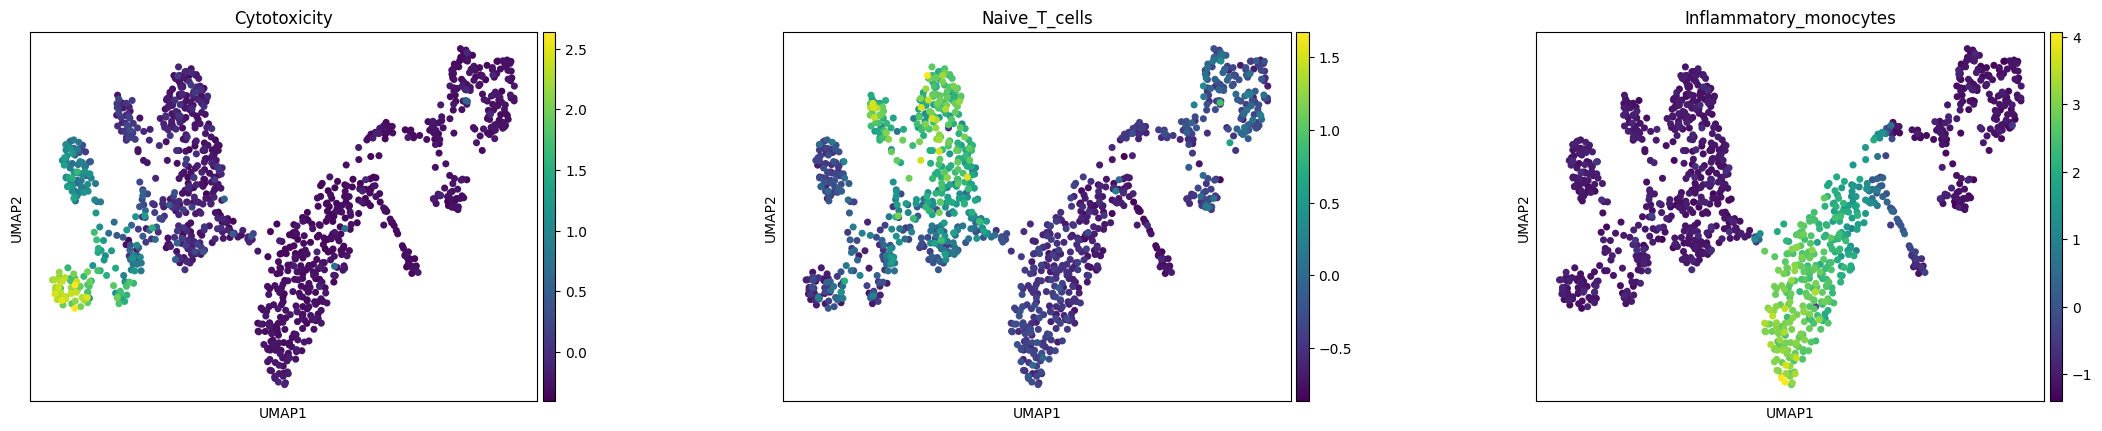

In [39]:
# Визуализация трёх генных программ на UMAP
sc.pl.umap(
    adata,
    color=[
        "Cytotoxicity",
        "Naive_T_cells",
        "Inflammatory_monocytes"
    ],
    ncols=3,
    cmap="viridis",
    wspace=0.35
)

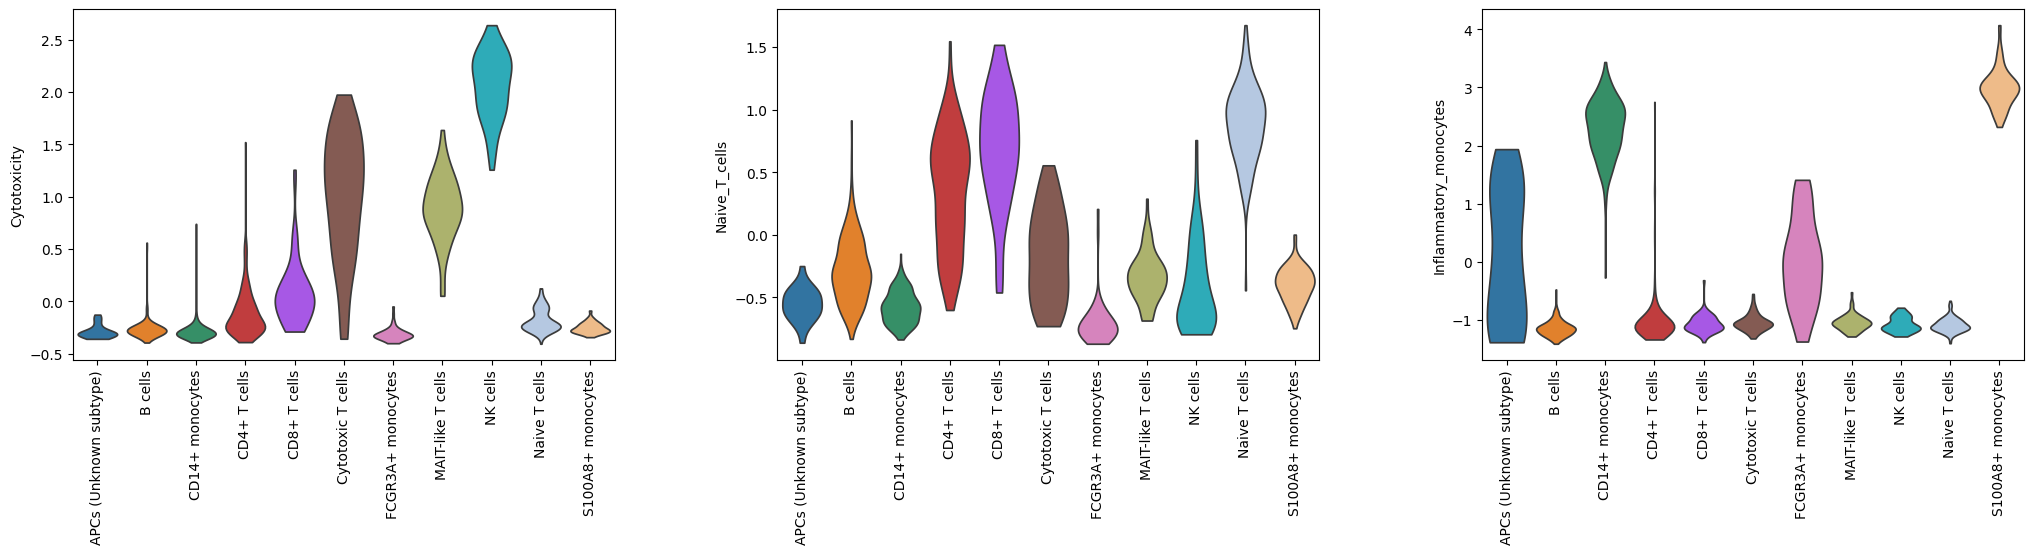

In [41]:
# Распределение Gene Scores по клеточным типам
sc.pl.violin(
    adata,
    keys=[
        "Cytotoxicity",
        "Naive_T_cells",
        "Inflammatory_monocytes"
    ],
    groupby="manual_cell_type",
    rotation=90,
    multi_panel=True,
    stripplot=False
)

In [42]:
# Средние Gene Scores по клеточным типам
mean_scores = (
    adata.obs
    .groupby("manual_cell_type", observed=True)[list(gene_programs.keys())]
    .mean()
)

for program in gene_programs:
    print(f"\n{program}:")
    display(
        mean_scores[[program]]
        .sort_values(program, ascending=False)
        .head(5)
        .round(3)
    )


Cytotoxicity:


,Cytotoxicity
manual_cell_type,
NK cells,2.063
Cytotoxic T cells,1.002
MAIT-like T cells,0.889
CD8+ T cells,0.080
CD4+ T cells,-0.115



Naive_T_cells:


,Naive_T_cells
manual_cell_type,
Naive T cells,0.888
CD8+ T cells,0.691
CD4+ T cells,0.348
Cytotoxic T cells,-0.162
B cells,-0.278



Inflammatory_monocytes:


,Inflammatory_monocytes
manual_cell_type,
S100A8+ monocytes,2.987
CD14+ monocytes,2.300
APCs (Unknown subtype),0.087
FCGR3A+ monocytes,0.003
CD4+ T cells,-1.018


##Ответы и ркзультаты

**1. Выбор генных программ**

Выбраны три набора генов на основе известных маркеров клеточных функций и состояний:

- **Цитотоксичность:** `PRF1`, `GZMA`, `CTSW`, `KLRD1`.
- **Наивное состояние T-клеток:** `CCR7`, `SELL`, `TCF7`, `LEF1`.
- **Воспалительная программа моноцитов:** `S100A8`, `S100A9`, `S100A12`, `VCAN`.

Все 12 генов присутствуют в датасете. Наборы составлены на основе известных биологических функций генов и выбраны с учётом клеточных популяций PBMC.

**2. Расчёт и визуализация**

С помощью `sc.tl.score_genes()` рассчитаны оценки трёх программ для 1161 клетки. Построены UMAP и violin plots, показывающие распределение Gene Scores между клеточными популяциями.

**3–4. Клеточные популяции с наиболее высокими scores**

| Программа | Популяции с наиболее высокими средними scores |
|---|---|
| Цитотоксичность | NK cells (2,063), Cytotoxic T cells (1,002), MAIT-like T cells (0,889) |
| Наивные T-клетки | Naive T cells (0,888), CD8+ T cells (0,691), CD4+ T cells (0,348) |
| Воспалительные моноциты | S100A8+ monocytes (2,987), CD14+ monocytes (2,300) |

**5. Сравнение с ручной аннотацией**

Результаты в целом подтверждают ручную аннотацию. Цитотоксическая программа наиболее выражена у NK-клеток и цитотоксических T-лимфоцитов. Программа наивного состояния характерна для Naive T cells, но также заметна у CD4+ и CD8+ T-клеток. Воспалительная программа позволяет отличить S100A8+ и CD14+ моноциты от FCGR3A+ моноцитов, у которых средний score близок к нулю (0,003).

**Главный вопрос. Как генные программы помогают уточнять аннотацию?**

Gene Scores позволяют оценивать не отдельные маркеры, а целые наборы генов, связанные с определёнными клеточными состояниями. Например, программа наивных T-клеток помогает выявлять различия внутри T-клеточных популяций, что согласуется с результатами субкластеризации CD4+ T-клеток. Воспалительная программа помогает различать подтипы моноцитов.

Таким образом, генные программы дополняют ручную аннотацию и позволяют уточнять функциональные состояния клеток. Однако высокий Gene Score отражает относительную экспрессию генов и сам по себе не доказывает выполнение биологической функции.

## Задание 8. Итоговые результаты и выводы

### 1. Исходная кластеризация

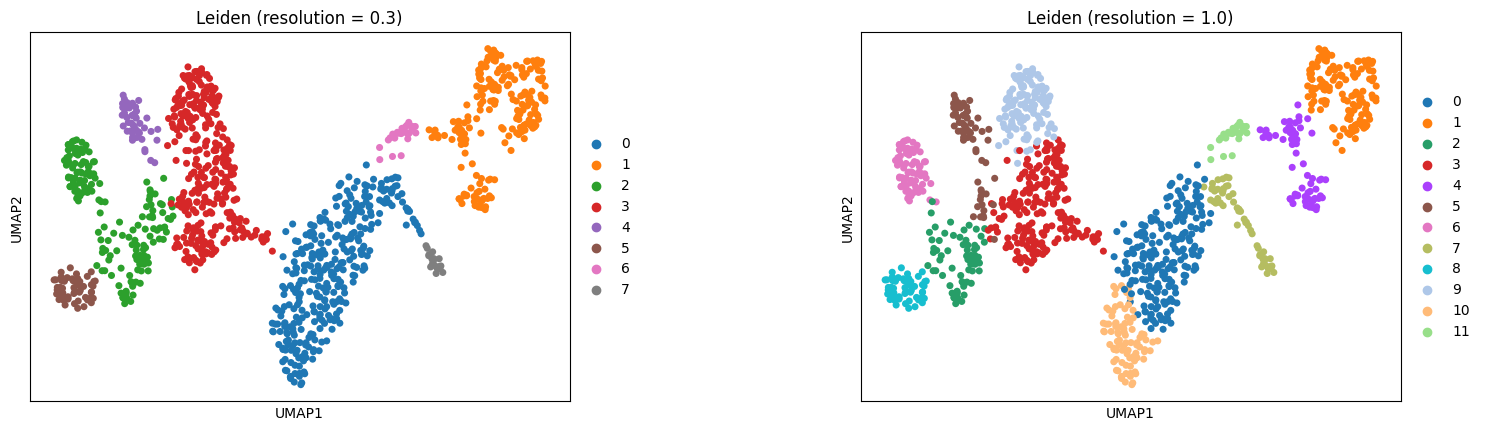

In [43]:
sc.pl.umap(
    adata,
    color=["leiden_0.3", "leiden_1.0"],
    title=["Leiden (resolution = 0.3)", "Leiden (resolution = 1.0)"],
    ncols=2,
    wspace=0.4
)

### 2. Ручная и автоматическая аннотация клеток

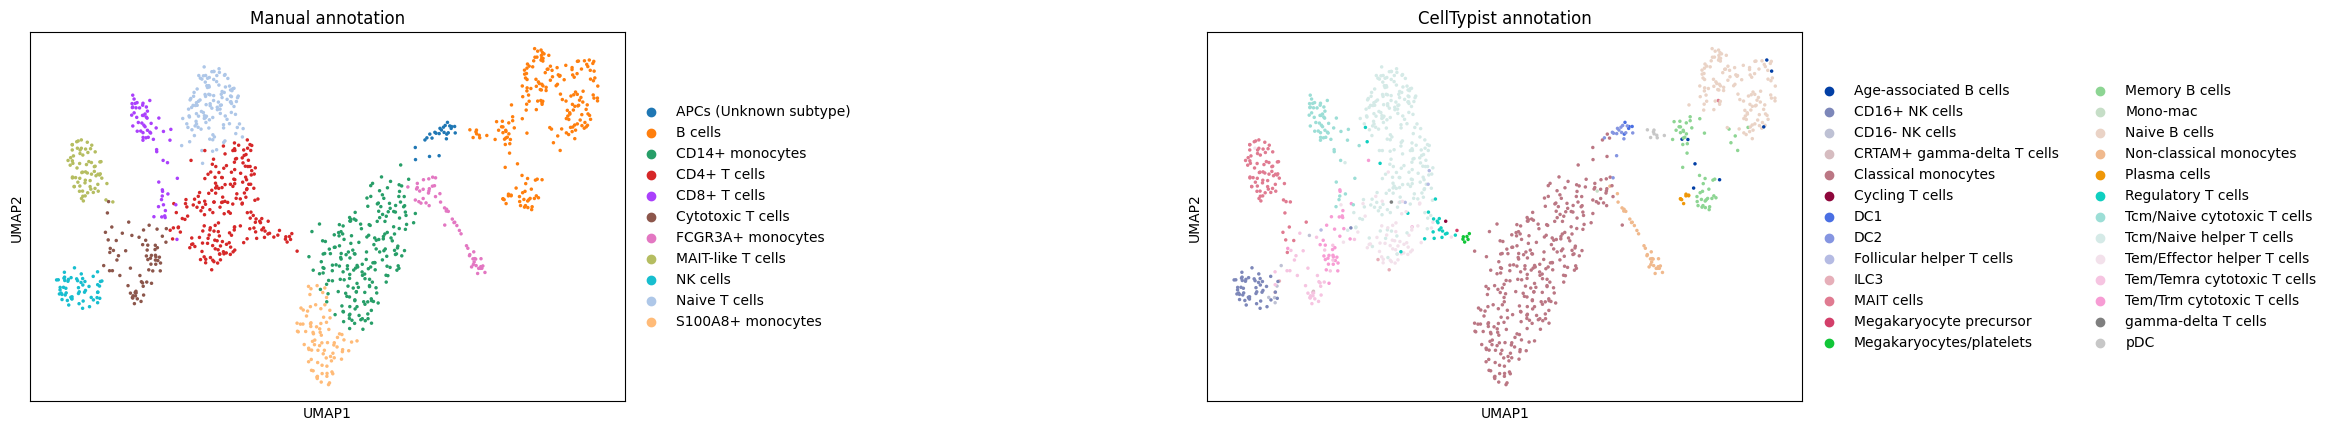

In [44]:
sc.pl.umap(
    adata,
    color=["manual_cell_type", "celltypist_cell_type"],
    title=["Manual annotation", "CellTypist annotation"],
    ncols=2,
    wspace=0.8,
    legend_loc="right margin",
    size=25
)

### 3. Основные маркерные гены

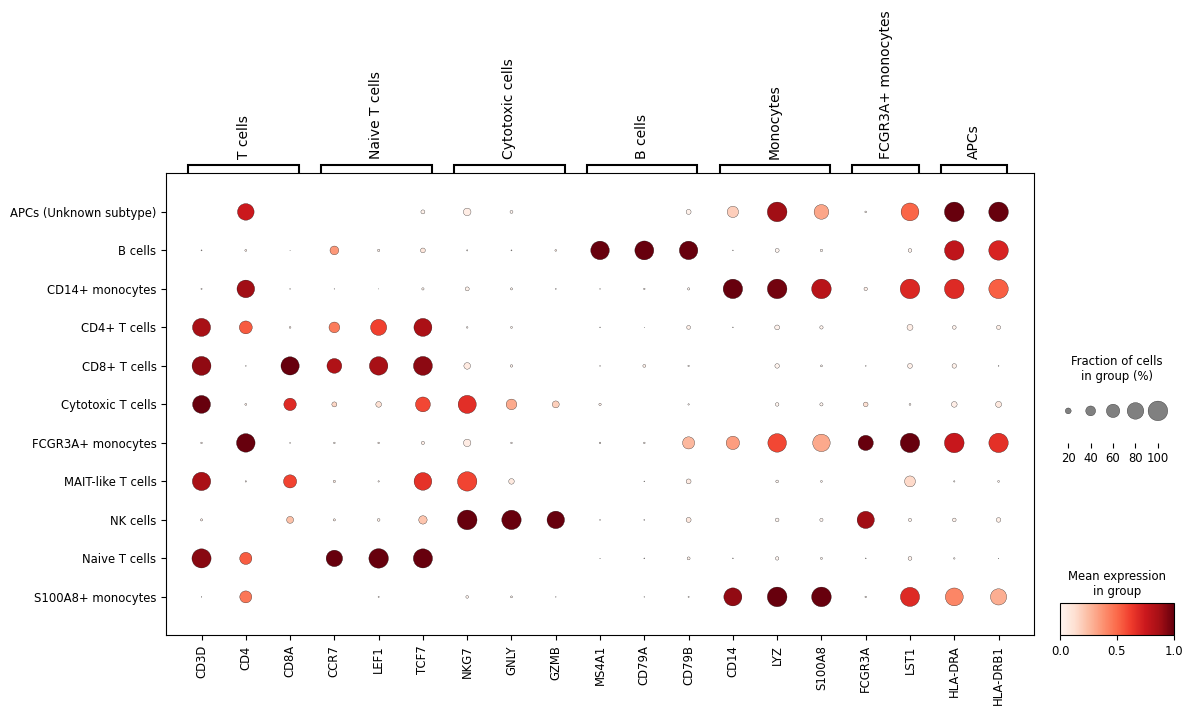

In [45]:
# Основные маркеры клеточных популяций
marker_genes = {
    "T cells": ["CD3D", "CD4", "CD8A"],
    "Naive T cells": ["CCR7", "LEF1", "TCF7"],
    "Cytotoxic cells": ["NKG7", "GNLY", "GZMB"],
    "B cells": ["MS4A1", "CD79A", "CD79B"],
    "Monocytes": ["CD14", "LYZ", "S100A8"],
    "FCGR3A+ monocytes": ["FCGR3A", "LST1"],
    "APCs": ["HLA-DRA", "HLA-DRB1"]
}

# Оставляем только гены, присутствующие в данных
marker_genes = {
    group: [gene for gene in genes if gene in adata.var_names]
    for group, genes in marker_genes.items()
}

sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby="manual_cell_type",
    standard_scale="var",
    figsize=(13, 6)
)

### 4. Субкластеризация CD4+ T-клеток

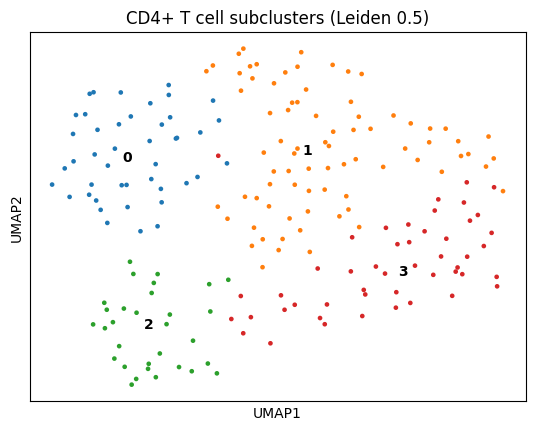

In [46]:
sc.pl.umap(
    adata_sub,
    color="subcluster",
    title="CD4+ T cell subclusters (Leiden 0.5)",
    legend_loc="on data",
    size=45
)

### 5. Генные программы

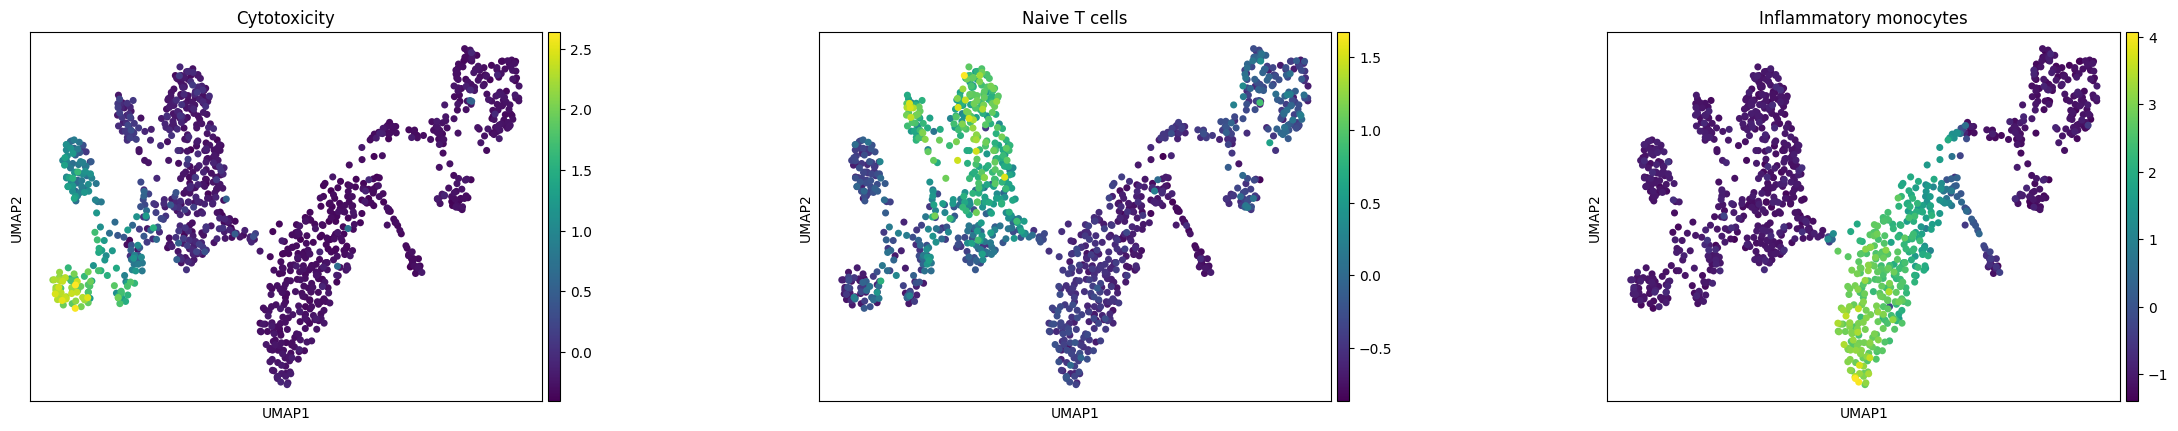

In [47]:
sc.pl.umap(
    adata,
    color=[
        "Cytotoxicity",
        "Naive_T_cells",
        "Inflammatory_monocytes"
    ],
    title=[
        "Cytotoxicity",
        "Naive T cells",
        "Inflammatory monocytes"
    ],
    ncols=3,
    cmap="viridis",
    wspace=0.4
)

### 6. Сравнение ручной и автоматической аннотации

In [48]:
# Сравнение ручной аннотации с CellTypist
comparison = pd.crosstab(
    adata.obs["manual_cell_type"],
    adata.obs["celltypist_cell_type"]
)

# Для каждой ручной группы находим наиболее частый тип CellTypist
comparison_summary = pd.DataFrame({
    "Manual annotation": comparison.index,
    "Most common CellTypist label": comparison.idxmax(axis=1).values,
    "Matching cells": comparison.max(axis=1).values,
    "Total cells": comparison.sum(axis=1).values
})

comparison_summary["Percentage (%)"] = (
    comparison_summary["Matching cells"]
    / comparison_summary["Total cells"] * 100
).round(1)

display(comparison_summary)

,Manual annotation,Most common CellTypist label,Matching cells,Total cells,Percentage (%)
0,APCs (Unknown subtype),DC2,14,25,56.0
1,B cells,Naive B cells,128,203,63.1
2,CD14+ monocytes,Classical monocytes,211,211,100.0
3,CD4+ T cells,Tcm/Naive helper T cells,107,201,53.2
4,CD8+ T cells,Tcm/Naive cytotoxic T cells,54,64,84.4
5,Cytotoxic T cells,Tem/Temra cytotoxic T cells,31,68,45.6
6,FCGR3A+ monocytes,Non-classical monocytes,33,55,60.0
7,MAIT-like T cells,MAIT cells,69,70,98.6
8,NK cells,CD16+ NK cells,48,56,85.7
9,Naive T cells,Tcm/Naive helper T cells,119,123,96.7


### Итого

**1. Какие основные клеточные популяции удалось обнаружить?**

В датасете из 1161 клетки обнаружены T-лимфоциты (CD4+, CD8+, цитотоксические, наивные и MAIT-like), B-клетки, NK-клетки и несколько популяций моноцитов. Также выделена небольшая группа антигенпрезентирующих клеток (APCs), точный подтип которой определить не удалось. При разрешении Leiden 0.3 получено 8 кластеров, при 1.0 — 12.

**2. Какие маркерные гены позволили их идентифицировать?**

- T-клетки — `CD3D`, `CD4`, `CD8A`.
- Наивные T-клетки — `CCR7`, `LEF1`, `TCF7`.
- Цитотоксические T- и NK-клетки — `NKG7`, `GNLY`, `GZMB`.
- B-клетки — `MS4A1`, `CD79A`, `CD79B`.
- Моноциты — `CD14`, `LYZ`, `S100A8`, `FCGR3A`.
- APCs — `HLA-DRA`, `HLA-DRB1`.

**3. Насколько согласуются ручная и автоматическая аннотации?**

В целом результаты согласуются. CellTypist подтвердил основные клеточные популяции, но выделил больше подтипов. Например, среди CD14+ и S100A8+ моноцитов по 100% клеток отнесены к классическим моноцитам, среди MAIT-like T-клеток 98,6% определены как MAIT cells, а среди наивных T-клеток 96,7% — как Tcm/Naive helper T cells. У CD4+ и цитотоксических T-клеток согласование отдельных меток ниже из-за большей неоднородности этих групп.

Эти проценты показывают долю клеток с наиболее распространённой меткой CellTypist внутри каждой ручной группы, но не являются оценкой точности аннотации.

**4. Что удалось обнаружить при субкластеризации?**

При повторной кластеризации 201 CD4+ T-клетки выделены четыре субкластера. Среди них обнаружены группы, обогащённые эффекторными, наивными/центральными и регуляторными T-клетками. Различия подтверждаются маркерами `IL7R`, `LEF1`, `TCF7`, `FOXP3`, `IL2RA` и результатами CellTypist. Это показывает, что внутри одного исходного кластера могут находиться клетки с разными состояниями.

**5. Какие дополнительные сведения о клетках дали генные программы?**

Были исследованы три программы: цитотоксичность, наивное состояние T-клеток и воспалительная программа моноцитов.

- Цитотоксичность наиболее выражена у NK-клеток (2,063), цитотоксических T-клеток (1,002) и MAIT-like T-клеток (0,889).
- Программа наивного состояния наиболее выражена у Naive T cells (0,888), но также заметна у CD8+ (0,691) и CD4+ T-клеток (0,348).
- Воспалительная программа наиболее выражена у S100A8+ (2,987) и CD14+ моноцитов (2,300), но значительно слабее у FCGR3A+ моноцитов (0,003).

Генные программы помогли уточнить функциональные различия между популяциями и выявить неоднородность внутри некоторых клеточных групп. При этом Gene Scores отражают относительную экспрессию генов, а не прямое доказательство активности соответствующих процессов.

**Общий вывод**

Анализ scRNA-seq позволил выделить основные иммунные популяции PBMC и охарактеризовать их по маркерным генам. Ручная и автоматическая аннотации в целом согласуются, а субкластеризация и Gene Scores помогают дополнительно различать клеточные подтипы и состояния.